# SMS Guard: модели и сохранённые результаты
Фиксированные результаты реальных экспериментов. Notebook не выполняет повторную финальную оценку test. Все графики ROC/PR относятся к validation. Метрики test читаются из сохранённого однократного отчёта.

In [1]:
import sys
from pathlib import Path

ROOT = Path.cwd()
if not (ROOT / "ml").exists():
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT))
import json
import subprocess
import time

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display
from sklearn.metrics import precision_recall_curve, roc_curve

from ml.data.load_sms import write_json
from ml.inference import ModelStore
from ml.preprocessing import normalize_sms
from ml.sms_experiment import load_partition

sms = json.loads((ROOT / "docs/reports/07_selection.json").read_text(encoding="utf-8"))
final = json.loads((ROOT / "docs/reports/07_final_test.json").read_text(encoding="utf-8"))
url = json.loads((ROOT / "docs/reports/url_experiment.json").read_text(encoding="utf-8"))
display(
    pd.DataFrame(
        [
            {
                "algorithm": r["algorithm"],
                "parameter": r["parameter"],
                **{k: v for k, v in r["validation"].items() if isinstance(v, (int, float))},
            }
            for r in sms["comparison"]
        ]
    )
)
display(
    pd.DataFrame(
        [
            {
                "algorithm": r["name"],
                **{k: v for k, v in r["validation"].items() if isinstance(v, (int, float))},
            }
            for r in url["comparison"]
        ]
    )
)
print("SMS test:", final["metrics"])
print("URL test:", url["test"])

,algorithm,parameter,accuracy,precision,recall,f1,f2,roc_auc,pr_auc,average_precision,threshold
0,MultinomialNB,0.1,0.989610,0.946809,0.967391,0.956989,0.963203,0.993571,0.979044,0.979102,0.375086
1,LogisticRegression,10.0,0.983117,0.891089,0.978261,0.932642,0.959488,0.996008,0.984940,0.984986,0.033683
2,CalibratedLinearSVM,10.0,0.987013,0.918367,0.978261,0.947368,0.965665,0.997515,0.989027,0.989067,0.113562


,algorithm,accuracy,precision,recall,f1,f2,roc_auc,pr_auc,average_precision,threshold
0,LR_C1,0.854560,0.851748,0.901164,0.875760,0.890827,0.942080,0.967179,0.966994,0.249566
1,LR_C10,0.856338,0.854390,0.900990,0.877071,0.891268,0.943050,0.967965,0.967779,0.250917
2,RF_depth12,0.857919,0.853958,0.904985,0.878732,0.894298,0.944799,0.968895,0.968698,0.288145
3,RF_depth24,0.856734,0.856599,0.898558,0.877077,0.889841,0.940554,0.966447,0.966061,0.302382


SMS test: {'accuracy': 0.9857328145265889, 'precision': 0.9361702127659575, 'recall': 0.946236559139785, 'f1': 0.9411764705882353, 'f2': 0.944206008583691, 'roc_auc': 0.9960351444793352, 'pr_auc': 0.9855890864817883, 'average_precision': 0.9856357946078371, 'macro': {'precision': 0.9643923441968636, 'recall': 0.9686935008088305, 'f1': 0.9665291947037118}, 'by_class': {'ham': {'precision': 0.9926144756277696, 'recall': 0.9911504424778761, 'f1': 0.9918819188191882, 'support': 678}, 'spam': {'precision': 0.9361702127659575, 'recall': 0.946236559139785, 'f1': 0.9411764705882353, 'support': 93}}, 'confusion_matrix': [[672, 6], [5, 88]], 'threshold': 0.11356167328234269}
URL test: {'accuracy': 0.7711305414940942, 'precision': 0.6424689440993789, 'recall': 0.743486073674753, 'f1': 0.6892961266139108, 'f2': 0.7208188153310104, 'roc_auc': 0.8447089633158222, 'pr_auc': 0.8357032139809902, 'average_precision': 0.8349339445990973, 'macro': {'precision': 0.7488276751945031, 'recall': 0.764475391833

## ROC и PR кривые SMS на validation; матрицы ошибок сохранённого test

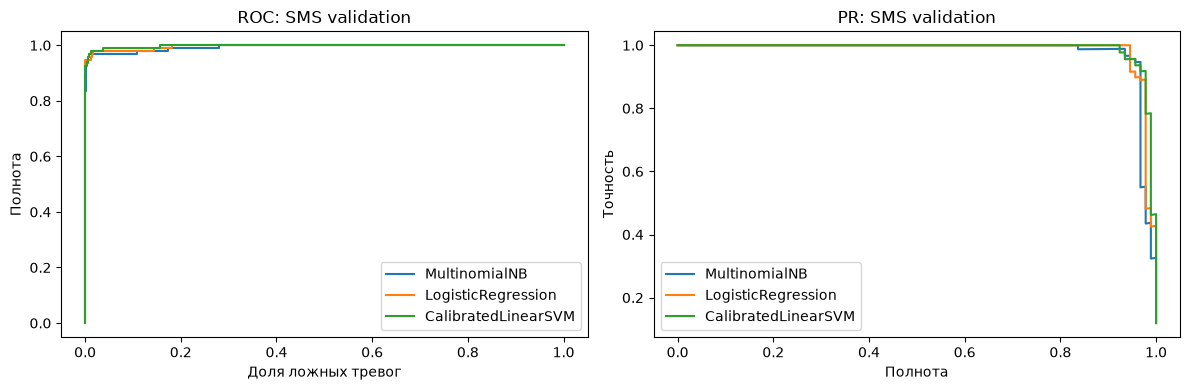

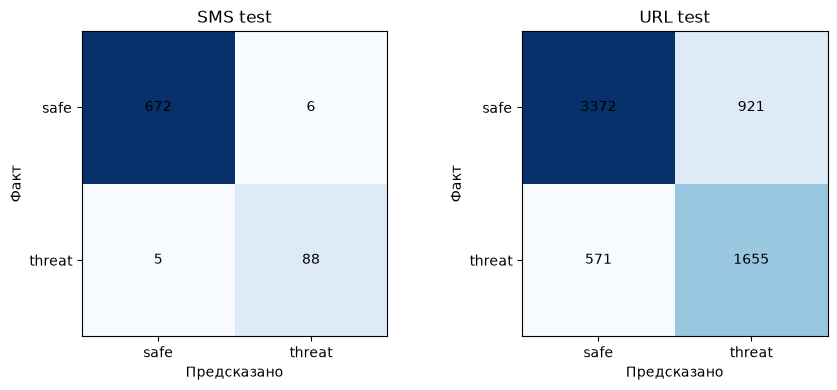

In [2]:
val = load_partition(ROOT, "val")
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for row in sms["comparison"]:
    p = np.load(ROOT / f"data/processed/07_val_{row['algorithm']}.npy")
    fpr, tpr, _ = roc_curve(val.label, p)
    precision, recall, _ = precision_recall_curve(val.label, p)
    axes[0].plot(fpr, tpr, label=row["algorithm"])
    axes[1].plot(recall, precision, label=row["algorithm"])
axes[0].set(xlabel="Доля ложных тревог", ylabel="Полнота", title="ROC: SMS validation")
axes[1].set(xlabel="Полнота", ylabel="Точность", title="PR: SMS validation")
for ax in axes:
    ax.legend()
fig.tight_layout()
fig.savefig(ROOT / "docs/figures/sms_roc_pr.png", dpi=130)
plt.show()
fig, axes = plt.subplots(1, 2, figsize=(9, 4))
for ax, title, values in [
    (axes[0], "SMS test", final["metrics"]["confusion_matrix"]),
    (axes[1], "URL test", url["test"]["confusion_matrix"]),
]:
    a = np.array(values)
    ax.imshow(a, cmap="Blues")
    ax.set(title=title, xlabel="Предсказано", ylabel="Факт")
    ax.set_xticks([0, 1], ["safe", "threat"])
    ax.set_yticks([0, 1], ["safe", "threat"])
    for i in range(2):
        for j in range(2):
            ax.text(j, i, str(a[i, j]), ha="center", va="center")
fig.tight_layout()
fig.savefig(ROOT / "docs/figures/model_confusion.png", dpi=130)
plt.show()

## Ошибки SMS: анализ сохранённых test-предсказаний, без повторного inference или настройки

In [3]:
test = load_partition(ROOT, "test")
p = np.load(ROOT / "data/processed/07_test_probabilities.npy")
yhat = p >= sms["selected"]["validation"]["threshold"]
errors = []
for kind, mask in [
    ("FN", (test.label.to_numpy() == 1) & ~yhat),
    ("FP", (test.label.to_numpy() == 0) & yhat),
]:
    for i in np.flatnonzero(mask)[:5]:
        errors.append(
            {
                "kind": kind,
                "id": int(test.iloc[i].id),
                "text": normalize_sms(test.iloc[i].text_raw),
                "probability": float(p[i]),
                "comment": (
                    "Возможное пересечение лексики/шаблонов классов; "
                    "требует экспертной проверки, не доказанное объяснение модели"
                ),
            }
        )
display(pd.DataFrame(errors))
write_json(
    ROOT / "docs/reports/sms_errors.json",
    {"scope": "cached final predictions; no test retuning", "errors": errors},
)

,kind,id,text,probability,comment
0,FN,1639,<num> a$networks allow companies to bill for s...,0.022148,Возможное пересечение лексики/шаблонов классов...
1,FN,2775,how come it takes so little time for a child w...,0.004342,Возможное пересечение лексики/шаблонов классов...
2,FN,4950,"hi this is amy, we will be sending you a free ...",0.036056,Возможное пересечение лексики/шаблонов классов...
3,FN,5373,dating:i have had two of these. only started a...,0.095429,Возможное пересечение лексики/шаблонов классов...
4,FN,5452,"latest news! police station toilet stolen, cop...",0.080550,Возможное пересечение лексики/шаблонов классов...
5,FP,1507,total video converter free download type this ...,0.136478,Возможное пересечение лексики/шаблонов классов...
6,FP,1673,glad to see your reply.,0.549813,Возможное пересечение лексики/шаблонов классов...
7,FP,2290,dont you have message offer,0.127632,Возможное пересечение лексики/шаблонов классов...
8,FP,3850,can you plz tell me the ans. bslvyl sent via <...,0.327273,Возможное пересечение лексики/шаблонов классов...
9,FP,3940,when the first strike is a red one. the bird +...,0.400139,Возможное пересечение лексики/шаблонов классов...


## Reload в отдельном процессе и время inference (синтетические en-примеры, не test)

In [4]:
probes = [
    "Hello! See you at the library tomorrow.",
    "URGENT! Claim a cash prize at https://prize.test",
]
store = ModelStore(ROOT / "ml/artifacts")
expected = [store.predict_sms(t) for t in probes]
code = (
    "import json; from ml.inference import predict_sms; print(json.dumps([predict_sms(t) for t in "
    + repr(probes)
    + "]))"
)
actual = json.loads(subprocess.check_output([sys.executable, "-c", code], cwd=ROOT, text=True))
assert actual == expected
samples = []
for _ in range(20):
    start = time.perf_counter()
    store.predict_sms(probes[0])
    samples.append(1000 * (time.perf_counter() - start))
write_json(
    ROOT / "docs/reports/model_restart.json",
    {
        "identical_predictions_after_new_process": True,
        "sms_single_ms_median": float(np.median(samples)),
        "sms_single_ms_p95": float(np.percentile(samples, 95)),
    },
)
print("Separate-process predictions identical; median ms:", np.median(samples))
baseline = joblib.load(ROOT / "ml/artifacts/sms_baseline.joblib")
p1 = baseline.predict_proba(probes)
p2 = joblib.load(ROOT / "ml/artifacts/sms_baseline.joblib").predict_proba(probes)
assert np.array_equal(p1, p2)
print("Baseline reload identical")

Separate-process predictions identical; median ms: 10.722699997131713


Baseline reload identical


## URL: ROC и важность признаков
Графики строятся на validation. Сравнительные LR/RF повторно fit только train с уже зафиксированными параметрами; текущий выбор и test не меняются.

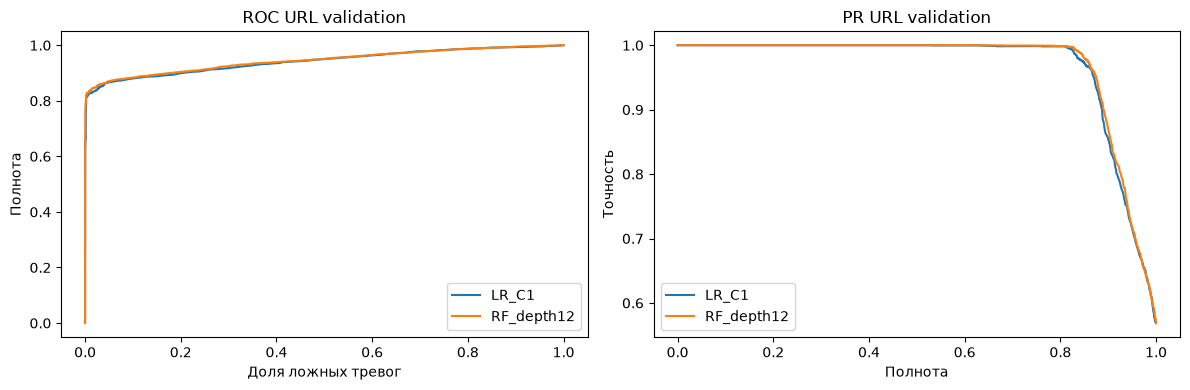

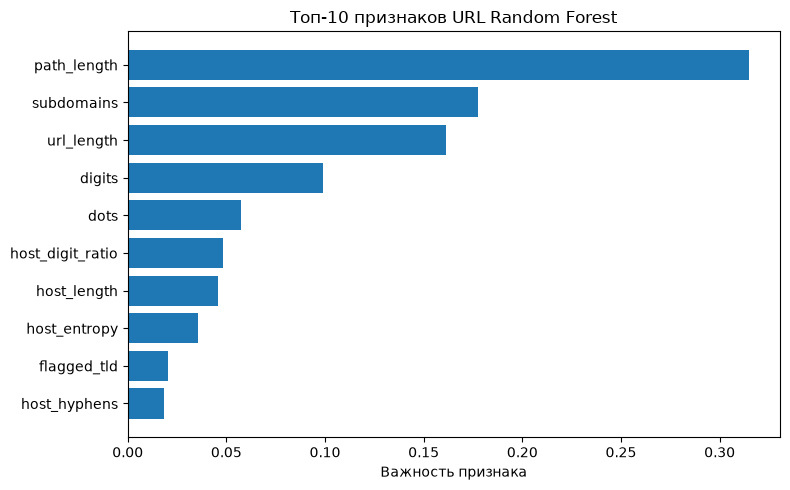

,url,probability,expected
0,google.com,0.273133,hypothesis only
1,microsoft.com,0.279731,hypothesis only
2,apple.com,0.278059,hypothesis only
3,amazon.com,0.272531,hypothesis only
4,paypal.com,0.278995,hypothesis only
5,github.com,0.292397,hypothesis only
6,wikipedia.org,0.277940,hypothesis only
7,python.org,0.289064,hypothesis only
8,mozilla.org,0.289544,hypothesis only
9,example.com,0.289544,hypothesis only


In [5]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

from ml.url_features import FEATURE_NAMES

url_features = pd.read_parquet(ROOT / "data/processed/url_features.parquet")
url_split = json.loads((ROOT / "data/processed/url_split.json").read_text())["positions"]
X = url_features[FEATURE_NAMES].to_numpy()
y = url_features.label.to_numpy()
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for name, model in [
    (
        "LR_C1",
        make_pipeline(
            StandardScaler(),
            LogisticRegression(C=1, max_iter=1000, class_weight="balanced", random_state=42),
        ),
    ),
    (
        "RF_depth12",
        RandomForestClassifier(
            n_estimators=150, max_depth=12, class_weight="balanced", n_jobs=2, random_state=42
        ),
    ),
]:
    model.fit(X[url_split["train"]], y[url_split["train"]])
    p = model.predict_proba(X[url_split["val"]])[:, 1]
    fpr, tpr, _ = roc_curve(y[url_split["val"]], p)
    precision, recall, _ = precision_recall_curve(y[url_split["val"]], p)
    axes[0].plot(fpr, tpr, label=name)
    axes[1].plot(recall, precision, label=name)
axes[0].set(title="ROC URL validation", xlabel="Доля ложных тревог", ylabel="Полнота")
axes[1].set(title="PR URL validation", xlabel="Полнота", ylabel="Точность")
for ax in axes:
    ax.legend()
fig.tight_layout()
fig.savefig(ROOT / "docs/figures/url_roc_pr.png", dpi=130)
plt.show()
url_model = joblib.load(ROOT / "ml/artifacts/url_model.joblib")
order = np.argsort(url_model.feature_importances_)[-10:]
fig, ax = plt.subplots(figsize=(8, 5))
ax.barh([FEATURE_NAMES[i] for i in order], url_model.feature_importances_[order])
ax.set(xlabel="Важность признака", title="Топ-10 признаков URL Random Forest")
fig.tight_layout()
fig.savefig(ROOT / "docs/figures/url_importance.png", dpi=130)
plt.show()
legitimate = [
    "google.com",
    "microsoft.com",
    "apple.com",
    "amazon.com",
    "paypal.com",
    "github.com",
    "wikipedia.org",
    "python.org",
    "mozilla.org",
    "example.com",
]
suspicious = [f"http://verify-bank-{i}.test/login?verify=1" for i in range(10)]
checks = [
    {"url": u, "probability": store.predict_url(u), "expected": "hypothesis only"}
    for u in legitimate + suspicious
]
write_json(
    ROOT / "docs/reports/url_synthetic20.json",
    {
        "note": "Synthetic URL strings, no pages opened; expectations are not model guarantees",
        "items": checks,
    },
)
display(pd.DataFrame(checks))

## Ограничения
SMS: английский spam не равен fraud. Русский — только правила и URL, без P_sms. URL-модель не достигла целевых test-метрик; групповой split изменил доли классов и строк. HTML/DNS-признаки не используются. Test не используется для дальнейшего улучшения. Полный ablation слов/символов/стоп-слов и отдельная экспертная валидация русского качества не проведены.